# Phase 2 - Probability and Distributions

How is mean bilateral entorhinal thickness related to CDR sum of boxes, and how do both vary by cognitive status?

In [1]:
from math import comb
from pathlib import Path
from statistics import NormalDist
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

## Participants

Each file has one row per participant. We match by `NACCID`. Visit dates are unavailable.

In [2]:
archive_path = Path("alzheimer(1).zip")
id_column = "NACCID"
status_column = "NACCUDSD"
score_column = "CDRSUM"
left_column = "LH_ENTORHINAL_AVGTH"
right_column = "RH_ENTORHINAL_AVGTH"

with ZipFile(archive_path) as archive:
    uds = pd.read_csv(
        archive.open("alzheimer/udslong_imputed.csv"),
        usecols=[id_column, status_column, score_column],
    )
    mri = pd.read_csv(
        archive.open("alzheimer/mriscanclean.csv"),
        usecols=[id_column, status_column, left_column, right_column],
    )

In [3]:
assert uds[id_column].notna().all()
assert mri[id_column].notna().all()
assert uds[id_column].is_unique
assert mri[id_column].is_unique

data = uds.merge(mri, on=id_column, validate="one_to_one", suffixes=("", "_mri"))
assert len(data) == len(uds) == len(mri)
assert data[status_column].eq(data["NACCUDSD_mri"]).all()
assert data[status_column].isin([1, 2, 3, 4]).all()

In [4]:
valid_scores = np.arange(0, 18.5, 0.5)
valid_scores = valid_scores[~np.isin(valid_scores, [16.5, 17.5])]

hemispheres = data[[left_column, right_column]]
valid_thickness = (hemispheres.gt(0) & np.isfinite(hemispheres)).all(axis=1)
valid_score = data[score_column].isin(valid_scores)
analysis = data.loc[valid_thickness & valid_score].copy()

X = (analysis[left_column] + analysis[right_column]) / 2
Y = analysis[score_column]
status = analysis[status_column].astype(int)
n = len(analysis)

sample_flow = pd.Series(
    {"UDS": len(uds), "MRI": len(mri), "Matched": len(data), "Analysis": n}
)
display(sample_flow)

UDS         1237
MRI         1237
Matched     1237
Analysis    1237
dtype: int64

## Events and variables

For one person drawn from the sample, $X$ is mean bilateral entorhinal thickness (mm) and $Y$ is the CDR sum of boxes.

$A = \{Y > 0\}$ and $B = \{X \leq 3\}$. The 3 mm split is the rounded Phase 1 mean and is used for descriptive grouping.

In [5]:
thickness_cutoff = 3.0
A = Y > 0
B = X <= thickness_cutoff

n_a = int(A.sum())
n_b = int(B.sum())
n_ab = int((A & B).sum())
n_a_only = n_a - n_ab
n_b_only = n_b - n_ab
n_neither = n - n_a - n_b + n_ab

event_counts = pd.DataFrame(
    [[n_ab, n_b_only, n_b], [n_a_only, n_neither, n - n_b],
     [n_a, n - n_a, n]],
    index=["B", "B complement", "Total"],
    columns=["A", "A complement", "Total"],
)
display(event_counts)

,A,A complement,Total
B,283,254,537
B complement,197,503,700
Total,480,757,1237


## Marginal, joint, and conditional probabilities

$$
P(A\mid B) = \frac{P(A\cap B)}{P(B)}
$$

In [6]:
p_a = n_a / n
p_b = n_b / n
p_ab = n_ab / n
p_a_given_b = n_ab / n_b
p_a_given_not_b = n_a_only / (n - n_b)
p_b_given_a = n_ab / n_a
p_ab_if_independent = p_a * p_b

probabilities = pd.DataFrame(
    {
        "Numerator": [n_a, n_b, n_ab, n_ab, n_a_only, n_ab],
        "Denominator": [n, n, n, n_b, n - n_b, n_a],
        "Probability": [p_a, p_b, p_ab, p_a_given_b, p_a_given_not_b, p_b_given_a],
    },
    index=["P(A)", "P(B)", "P(A and B)", "P(A|B)", "P(A|not B)", "P(B|A)"],
)
display(probabilities.round(6))

,Numerator,Denominator,Probability
P(A),480,1237,0.388036
P(B),537,1237,0.434115
P(A and B),283,1237,0.228779
P(A|B),283,537,0.527002
P(A|not B),197,700,0.281429
P(B|A),283,480,0.589583


## Independence

In [7]:
independence_comparison = pd.Series(
    {"P(A and B)": p_ab, "P(A) × P(B)": p_ab_if_independent}
)
display(independence_comparison.round(6))

P(A and B)     0.228779
P(A) × P(B)    0.168452
dtype: float64

## Binomial model

$K$ counts scores above zero in 20 draws with replacement.

$$
P(K=8) = \binom{20}{8}p^{8}(1-p)^{12}
$$

In [8]:
draws = 20
k = 8
p_eight = comb(draws, k) * p_a**k * (1 - p_a)**(draws - k)
display(pd.Series({"P(K = 8)": p_eight}).round(6))

P(K = 8)    0.17863
dtype: float64

In [9]:
figure_dir = Path("figures/phase2")
table_dir = Path("tables/phase2")
figure_dir.mkdir(parents=True, exist_ok=True)
table_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "svg.hashsalt": "amar-phase2",
})

blue = "#2d6171"
red = "#a75339"


def save_figure(figure, filename):
    path = figure_dir / filename
    figure.savefig(path, metadata={"Date": None})
    lines = path.read_text(encoding="utf-8").splitlines()
    path.write_text("".join(line.rstrip() + "\n" for line in lines), encoding="utf-8")

## Thickness and the normal distribution

In [10]:
mean_x = X.mean()
var_x = X.var(ddof=0)
normal_x = NormalDist(mean_x, np.sqrt(var_x))
grid = np.linspace(X.min(), X.max(), 250)
normal_density = [normal_x.pdf(value) for value in grid]

positions = (np.arange(n) + 0.5) / n
normal_quantiles = [normal_x.inv_cdf(p) for p in positions]
observed_quantiles = np.sort(X)

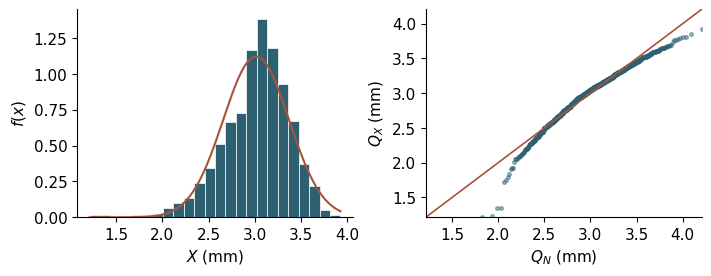

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.65), layout="constrained")
axes[0].hist(X, bins=24, density=True, color=blue, edgecolor="white", linewidth=0.5)
axes[0].plot(grid, normal_density, color=red, linewidth=1.5)
axes[0].set(xlabel="$X$ (mm)", ylabel="$f(x)$")

axes[1].scatter(normal_quantiles, observed_quantiles, s=7, alpha=0.45, color=blue)
limit = [min(min(normal_quantiles), X.min()), max(max(normal_quantiles), X.max())]
axes[1].plot(limit, limit, color=red, linewidth=1.2)
axes[1].set(xlabel="$Q_{N}$ (mm)", ylabel="$Q_{X}$ (mm)", xlim=limit, ylim=limit)

save_figure(fig, "thickness_normal.svg")
display(fig)
plt.close(fig)

## Mean, variance, and outliers

The empirical variance uses $n$ as its denominator.

In [12]:
values = pd.DataFrame({"CDRSUM": Y, "Thickness_mm": X})
first_quartile = values.quantile(0.25)
third_quartile = values.quantile(0.75)
iqr = third_quartile - first_quartile
lower_fence = first_quartile - 1.5 * iqr
upper_fence = third_quartile + 1.5 * iqr

moments = pd.DataFrame({
    "Mean": values.mean(),
    "Variance": values.var(ddof=0),
    "Minimum": values.min(),
    "Q1": first_quartile,
    "Median": values.median(),
    "Q3": third_quartile,
    "Maximum": values.max(),
    "Lower fence": lower_fence,
    "Upper fence": upper_fence,
    "Below lower fence": values.lt(lower_fence).sum(),
    "Above upper fence": values.gt(upper_fence).sum(),
})
display(moments.round(6))

,Mean,Variance,Minimum,Q1,Median,Q3,Maximum,Lower fence,Upper fence,Below lower fence,Above upper fence
CDRSUM,0.822150,2.966348,0.000,0.0000,0.0000,1.0000,15.000,-1.500,2.500,0,115
Thickness_mm,3.013763,0.126702,1.214,2.8025,3.0575,3.2515,3.925,2.129,3.925,22,0


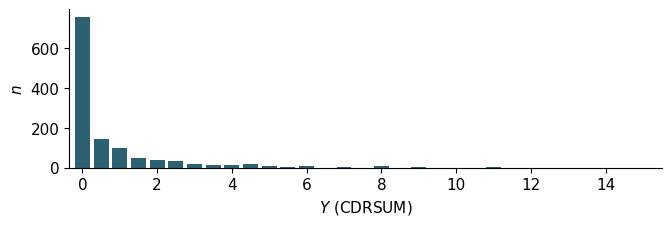

In [13]:
score_frequencies = Y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6.6, 2.15), layout="constrained")
ax.bar(score_frequencies.index, score_frequencies, color=blue, width=0.4)
ax.set(xlabel="$Y$ (CDRSUM)", ylabel="$n$", xlim=(-0.35, 15.5))
save_figure(fig, "cdrsum.svg")
display(fig)
plt.close(fig)

## Scatter plot and covariance

Cov(X, Y)   -0.178813
dtype: float64

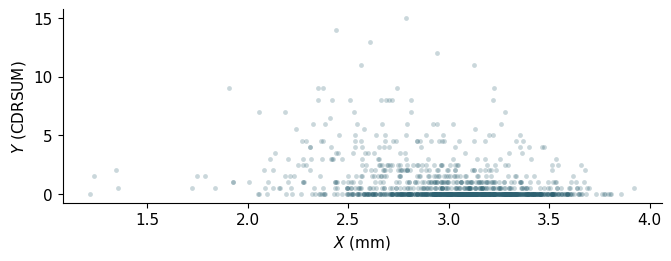

In [14]:
covariance = ((X - X.mean()) * (Y - Y.mean())).mean()
display(pd.Series({"Cov(X, Y)": covariance}).round(6))

fig, ax = plt.subplots(figsize=(6.6, 2.5), layout="constrained")
ax.scatter(X, Y, s=12, alpha=0.25, color=blue, linewidths=0)
ax.set(xlabel="$X$ (mm)", ylabel="$Y$ (CDRSUM)")
save_figure(fig, "covariance.svg")
display(fig)
plt.close(fig)

## Bayes' rule

$$
P(A\mid B) = \frac{P(B\mid A)\,P(A)}{P(B)}
$$

In [15]:
p_a_given_b_bayes = p_b_given_a * p_a / p_b
assert np.isclose(p_a_given_b_bayes, p_a_given_b)
display(pd.Series({
    "P(A)": p_a,
    "P(B|A)": p_b_given_a,
    "P(B)": p_b,
    "P(A|B) via Bayes": p_a_given_b_bayes,
}).round(6))

P(A)                0.388036
P(B|A)              0.589583
P(B)                0.434115
P(A|B) via Bayes    0.527002
dtype: float64

## Cognitive status by thickness group

Codes 1–4: normal, impaired without MCI, mild cognitive impairment (MCI), dementia.

In [16]:
status_counts = pd.crosstab(status, B).reindex(
    index=[1, 2, 3, 4], columns=[True, False], fill_value=0
)
status_counts.columns = ["N given B", "N given not B"]

by_status = values.groupby(status).agg(
    median_cdr=("CDRSUM", "median"),
    median_thickness_mm=("Thickness_mm", "median"),
)

status_summary = status_counts.copy()
status_summary["N"] = status_counts.sum(axis=1)
status_summary["P(status|B)"] = status_counts["N given B"] / n_b
status_summary["P(status|not B)"] = status_counts["N given not B"] / (n - n_b)
status_summary = status_summary.join(by_status)
display(status_summary.round(6))

,N given B,N given not B,N,P(status|B),P(status|not B),median_cdr,median_thickness_mm
NACCUDSD,,,,,,,
1,292,555,847,0.543762,0.792857,0.0,3.1030
2,1,6,7,0.001862,0.008571,1.0,3.1880
3,141,111,252,0.262570,0.158571,1.0,2.9655
4,103,28,131,0.191806,0.040000,4.5,2.6905


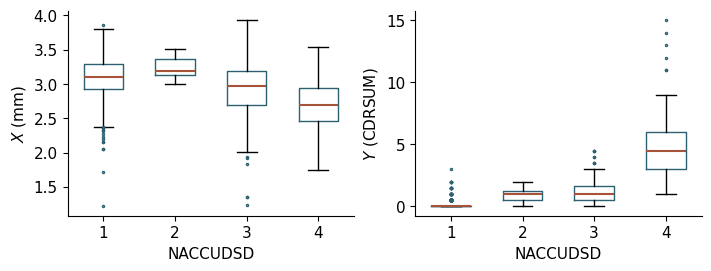

In [17]:
status_codes = [1, 2, 3, 4]
score_groups = [Y[status.eq(code)] for code in status_codes]
thickness_groups = [X[status.eq(code)] for code in status_codes]

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6), layout="constrained")
for ax, groups, label in zip(
    axes, [thickness_groups, score_groups], ["$X$ (mm)", "$Y$ (CDRSUM)"]
):
    ax.boxplot(
        groups,
        widths=0.55,
        medianprops={"color": red, "linewidth": 1.5},
        boxprops={"color": blue},
        flierprops={"marker": ".", "markersize": 3, "markeredgecolor": blue},
    )
    ax.set(xlabel="NACCUDSD", ylabel=label, xticks=status_codes)

save_figure(fig, "by_status.svg")
display(fig)
plt.close(fig)

In [18]:
event_counts.to_csv(table_dir / "event_counts.csv", index_label="Thickness group")
probabilities.to_csv(table_dir / "probabilities.csv", index_label="Event")
moments.to_csv(table_dir / "empirical_moments.csv", index_label="Variable")
status_summary.to_csv(table_dir / "cognitive_status.csv", index_label="NACCUDSD")